In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from improc.io import parse_collection, DCAccessor

DCAccessor.register()

In [ ]:
df = pd.read_hdf('/tungstenfs/scratch/gliberal/Users/ortiraph/datasets/ISIT_test_data/40x/input_data_collection.h5', 'dc')
df

In [ ]:
for idx,subdf in df.groupby(['fname']):
    
    pred, raw = subdf.dc.read()
    raw = raw[0]
    
    step = 8

    plt.figure(figsize=(18,18))
    plt.imshow(raw[::step,::step], cmap='Greys_r')
#     plt.show()

#     plt.figure(figsize=(18,18))
    plt.imshow(pred[::step,::step], interpolation='nearest', alpha=0.75)
    plt.show()

In [6]:
df = pd.read_hdf('/tungstenfs/scratch/gliberal/Users/ortiraph/datasets/ISIT/2D_mip_org_seg/training_collection.h5', 'dc')

In [ ]:
df.dc[:,'20X_T144_crowded-area']

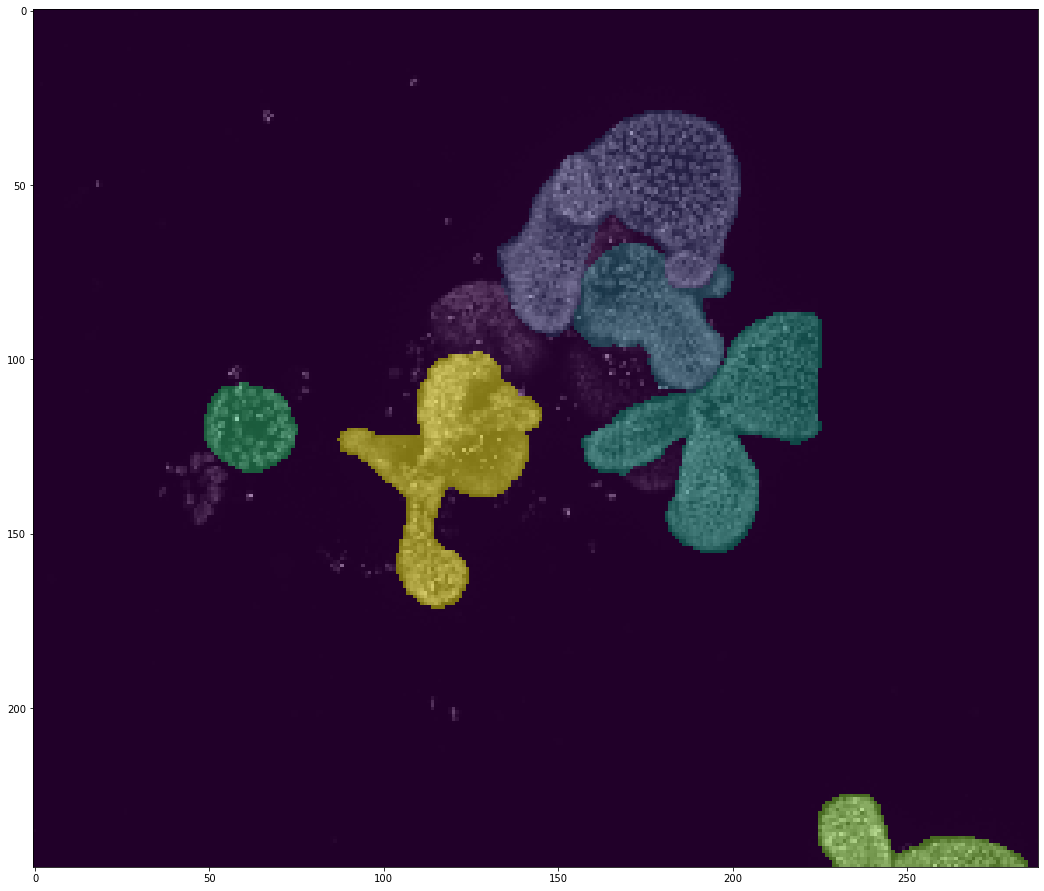

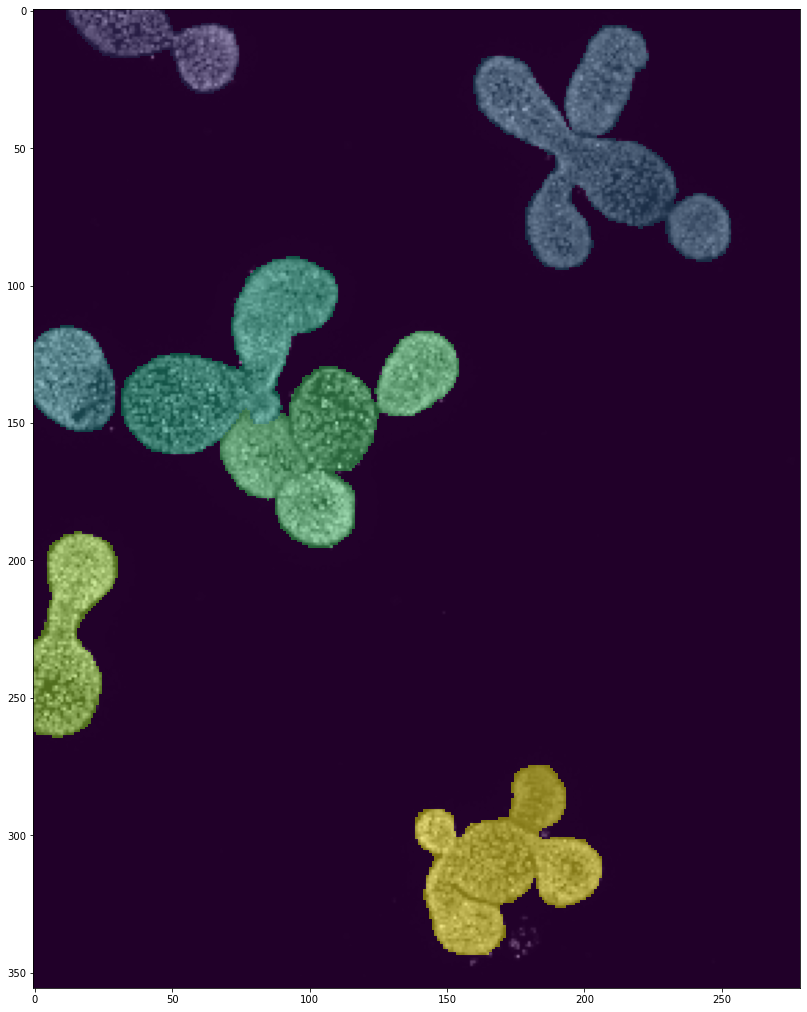

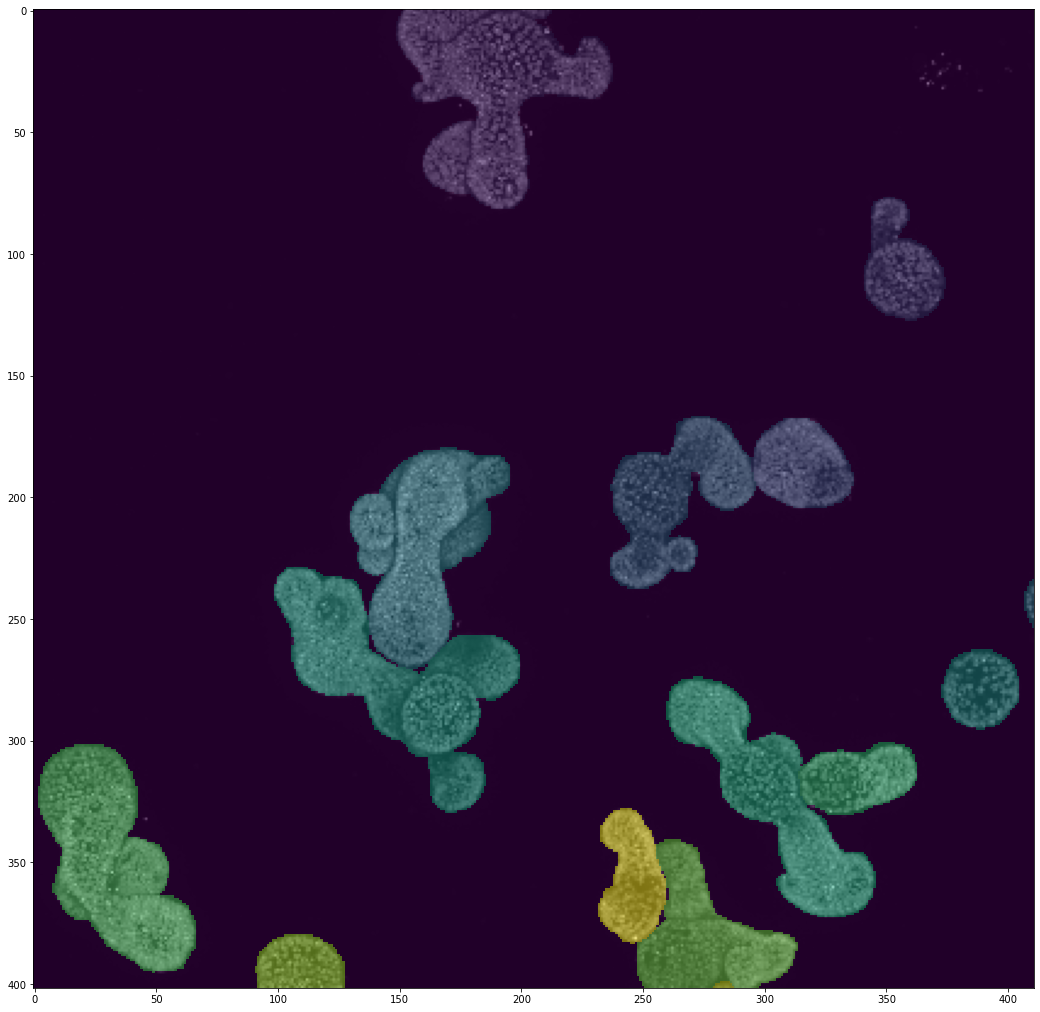

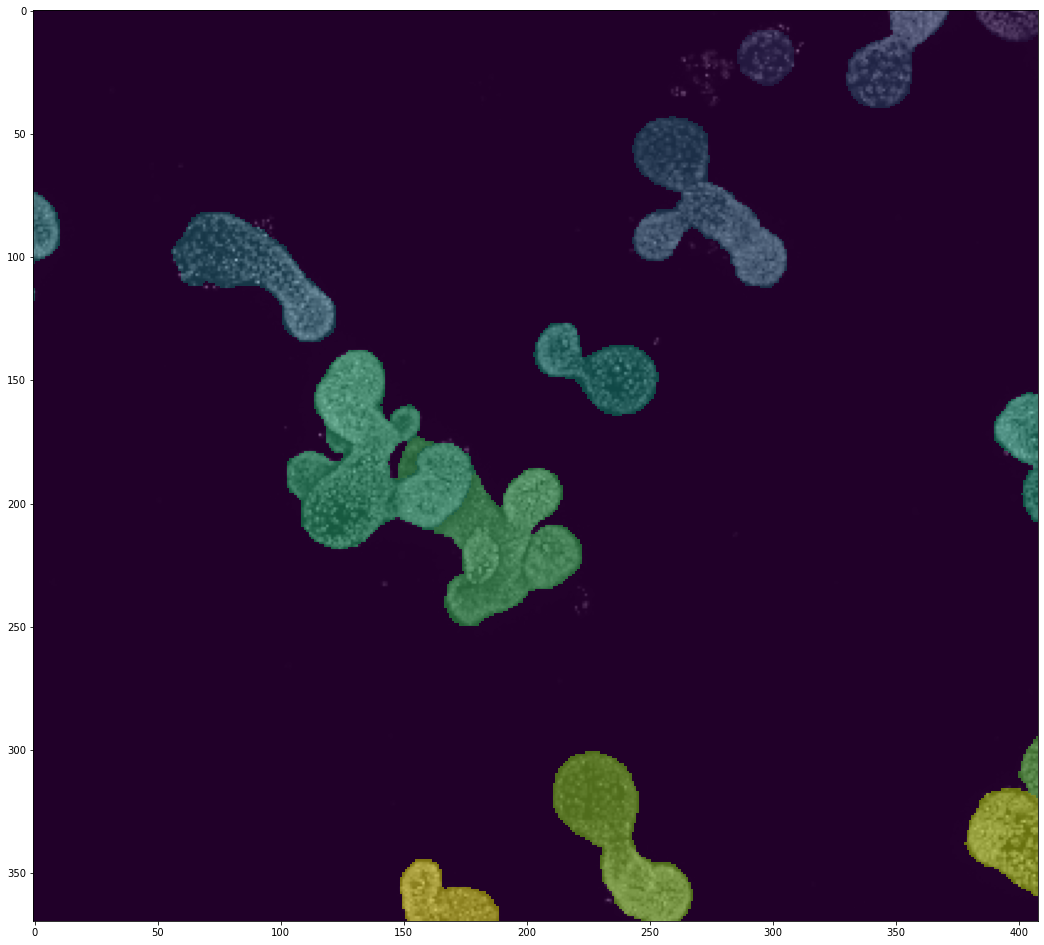

KeyboardInterrupt: 

In [10]:
step = 8

for idx,subdf in df.dc[:,:,'20X_T144_crowded-area'].groupby(['fname', 'subset']):
    annot, raw = subdf.dc.read()
    
    plt.figure(figsize=(18,18))
    plt.imshow(raw[::step,::step], cmap='Greys_r')
    plt.imshow(annot[::step,::step], interpolation='nearest', alpha=0.5)
    plt.show()
    
#     break

In [3]:
import tensorflow as tf

physical_devices = tf.config.experimental.list_physical_devices('GPU')
assert len(physical_devices) > 0, "Not enough GPU hardware devices available"
tf.config.experimental.set_memory_growth(physical_devices[0], True)

model_path = '/tungstenfs/scratch/gliberal/Users/ortiraph/datasets/ISIT/2D_mip_org_seg/training_output/RDCNet-F8-DC16-G4-DR1-2-4-8-16-GC32-S7-D0.1_20210324_inference'

model = tf.saved_model.load(model_path)

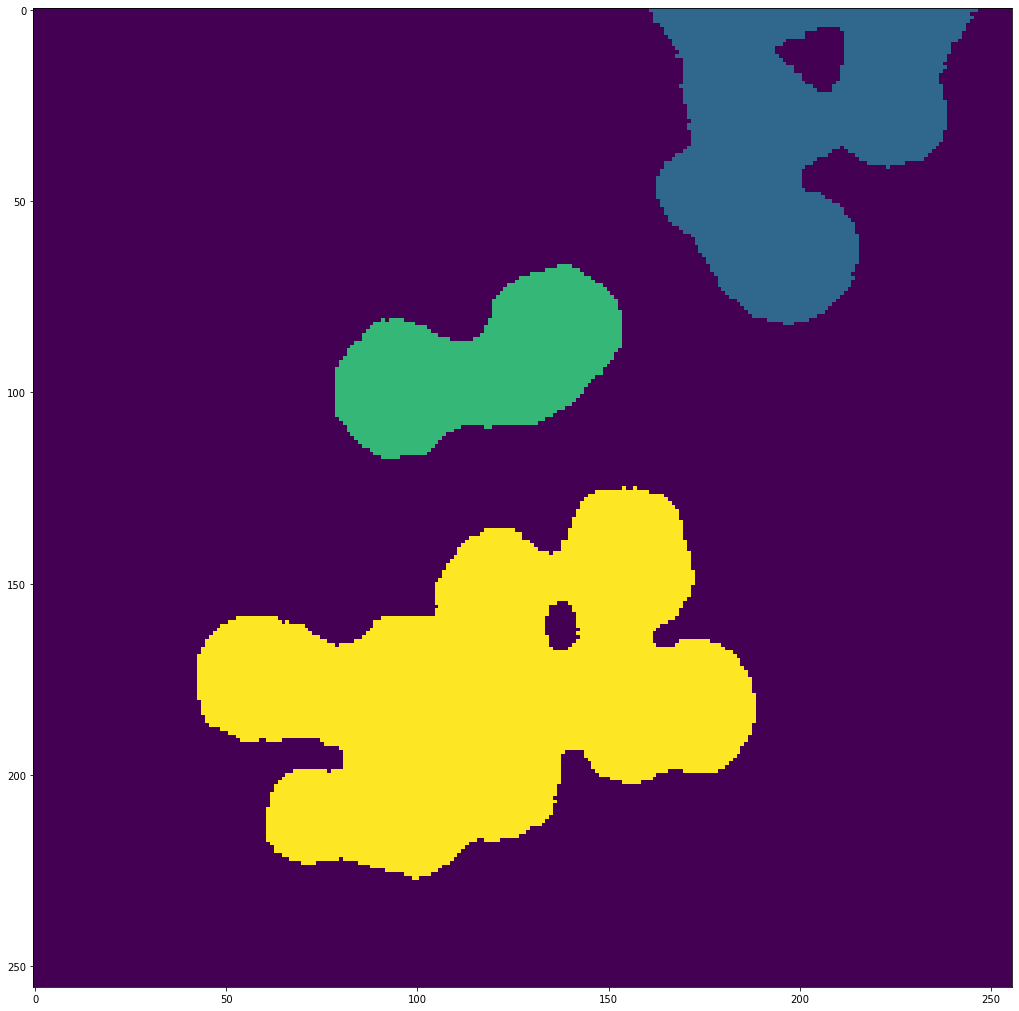

In [12]:
# raw = (np.random.rand(1485,1760)>0.5).astype(np.uint16)

predict_fn = model.signatures['pred_instance']
pred = predict_fn(tf.convert_to_tensor(raw[::8,::8][100:356,100:356]))['labels']

plt.figure(figsize=(18,18))
plt.imshow(pred, interpolation='nearest')
plt.show()

In [1]:
# from dlutils.layers.semi_conv import generate_coordinate_grid

# model_path = '/tungstenfs/scratch/gliberal/Users/ortiraph/datasets/ISIT/2D_mip_org_seg/training_output/RDCNet-F8-DC16-G4-DR1-2-4-8-16-GC32-S7-D0.1_20210324'

# model = tf.keras.models.load_model(model_path, compile=False)
# model.load_weights(os.path.join(model_path,'weights_latest.h5'))

# img = raw[::8,::8][:256,:256]

# img = tf.cast(img, tf.float32)
# img = img - tf.reduce_mean(img)
# img = img / tf.math.reduce_std(img)
# img = img[None, ..., None]

# # apply the actual model.
# embeddings, classes = model(img, training=False)

# coords = generate_coordinate_grid(tf.shape(embeddings), 2) * (0.322, 0.322)
# embeddings = embeddings  - coords

# classes = classes[0,...,1]


# plt.figure(figsize=(18,18))
# plt.imshow(embeddings[0,...,1], interpolation='nearest')
# plt.show()

In [9]:
model.signatures['get_model_spacing']()['spacing'].numpy()

array([2.576, 2.576], dtype=float32)

In [ ]:
1485, 1760

# smooth annots

In [ ]:
from improc.label import smooth_label_edges
from skimage.transform import resize
import numpy as np


step = 8
annot_down = annot[::step,::step]



annot_up = resize(annot_down, output_shape=annot.shape, order=0, preserve_range=True).astype(np.uint16)

plt.figure(figsize=(18,18))
plt.imshow(annot_up, interpolation='nearest')
plt.show()

sigma = np.max(np.array(annot.shape) / np.array(annot_down.shape))
sigma = sigma * np.sqrt(annot.ndim)
print(sigma)
annot_up_smth = smooth_label_edges(annot_up, sigma)


plt.figure(figsize=(18,18))
plt.imshow(annot_up_smth, interpolation='nearest')
plt.show()


plt.figure(figsize=(18,18))
plt.imshow((annot_up-annot_up_smth)!=0, interpolation='nearest')
plt.show()